Performing exploratory data analysis on the regression dataset with the goal of building an ML model that can predict the selected physicochemical property of organic molecules based on a SMILES input.

In [ ]:
! pip install deepchem

In [12]:
import deepchem as dc
import seaborn as sns
import numpy as np
import sklearn
import scipy
import matplotlib
print(dc.__version__)
print(sns.__version__)
print(np.__version__)
print(sklearn.__version__)
print(scipy.__version__)
print(matplotlib.__version__)

2.5.0
0.13.2
2.1.3
1.6.1
1.16.3
3.10.0


Going to use DeepChem lipofilicity dataset and justify this choise later in the report (briefly: useful property + sufficient data points). We apply the recommended splitting.

The dataset contains experimental logD values (octanol/water distribution coefficient at pH 7.4) which reflect molecular lipophilicity for around 4200 compounds from the ChEMBL database. Measured logD value ('exp') are used as the target variable.

In [3]:
tasks, datasets, transformers = dc.molnet.load_lipo(featurizer='GraphConv'
                                                  , transformer='normalization'
                                                  , splitter='scaffold')


In [4]:
tasks

['exp']

In [5]:
train_dataset, valid_dataset, test_dataset = datasets
train_dataset # 3360 compounds in the training dataset is a decent amount

<DiskDataset X.shape: (np.int64(3360),), y.shape: (np.int64(3360), np.int64(1)), w.shape: (np.int64(3360), np.int64(1)), task_names: ['exp']>

In [6]:
smiles = train_dataset.ids
smiles

array(['CC(C)NCC(O)COc1ccc(COCCOC(C)C)cc1', 'Cc1ccc(NC(=N)N)cc1C',
       'CC(C)C(=O)NCCNCC(O)COc1ccc(O)cc1', ...,
       'Cn1cnc(c1Sc2ncnc3nc[nH]c23)[N+](=O)[O-]',
       'OCCN1CCN(Cc2ccc3c(NC(=O)CC45CC6CC(CC(C6)C4)C5)c(Cl)ccc3n2)CC1',
       'OC(=O)c1cccnc1Nc2cccc(c2)C(F)(F)F'], dtype=object)

In [7]:
train_dataset.y[0]

array([-1.70348225])

We expect subsets to be distributed identically, so will focus only on the training data for the following exploratory steps for simplicity.

Data Quality

In [8]:
#from ml_fundamentals
from deepchem.feat import RDKitDescriptors
featurizer = RDKitDescriptors()
features = featurizer.featurize(smiles)
print(f"Number of generated molecular descriptors: {features.shape[1]}")

features = features[:, ~np.isnan(features).any(axis=0)]
print(f"Number of molecular descriptors without invalid values: {features.shape[1]}")

Number of generated molecular descriptors: 217
Number of molecular descriptors without invalid values: 217


In [9]:
#from ml_fundamentals
from sklearn.feature_selection import VarianceThreshold
selector = VarianceThreshold(threshold=0.0)
features = selector.fit_transform(features)
print(f"Number of molecular descriptors after removing zero-variance features: {features.shape[1]}")

Number of molecular descriptors after removing zero-variance features: 208


No invalid values found for 217 calculated molecular desciptors of which 208 are meaningful for the dataset.

Target Distribution

In [10]:
y = train_dataset.y[:, 0]

mean = np.mean(y)
median = np.median(y)
std = np.std(y)
minimum = np.min(y)
maximum = np.max(y)
q1 = np.percentile(y, 25)
q3 = np.percentile(y, 75)
iqr = q3 - q1

print(f"Mean (normalized data): {mean:.3f}")
print(f"Median: {median:.3f}")
print(f"Standard deviation (normalized data): {std:.3f}")
print(f"Minimum: {minimum:.3f}")
print(f"Q1 (25%): {q1:.3f}")
print(f"Q3 (75%): {q3:.3f}")
print(f"Maximum: {maximum:.3f}")

outliers = y[(y < q1 - 1.5 * iqr) | (y > q3 + 1.5 * iqr)]

print(f"Percentage of potential statistical outliers: {len(outliers) / len(y) * 100:.2f}%")

Mean (normalized data): 0.000
Median: 0.146
Standard deviation (normalized data): 1.000
Minimum: -3.025
Q1 (25%): -0.630
Q3 (75%): 0.774
Maximum: 1.930
Percentage of potential statistical outliers: 0.60%


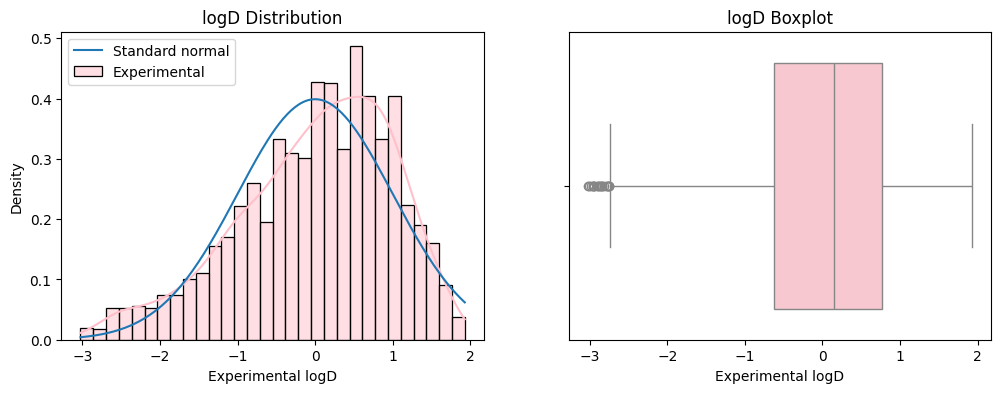

In [11]:
from scipy.stats import norm
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(y, bins=30, kde=True, color="pink", stat="density", label="Experimental", ax=axes[0])

x = np.linspace(min(y), max(y), 200)
axes[0].plot(x, norm.pdf(x, 0, 1), label="Standard normal")
axes[0].set_title("logD Distribution")
axes[0].set_xlabel("Experimental logD")
axes[0].legend()

sns.boxplot(y, orient='h', color="pink", ax=axes[1])
axes[1].set_title("logD Boxplot")
axes[1].set_xlabel("Experimental logD")

plt.show()

The target distribution is slightly skewed, with several extreme values on the lower side. These values are likely chemically meaningful, but they may make prediction more challenging.